# Online Retail — Full Data Analysis Project
### Pandas • Matplotlib • Seaborn • Plotly


**Dataset source:** [Online Retail Dataset — Kaggle](https://www.kaggle.com/datasets/vijayuv/onlineretail)

**Dataset facts:** The commonly distributed version contains approximately 541,909 transaction rows and fields such as invoice number, product code, description, quantity, invoice date, unit price, customer ID, and country. Your downloaded file may differ slightly, so always inspect it rather than assuming exact counts.



---

## 0. Environment setup and dataset loading

You can download the dataset through KaggleHub. If Kaggle authentication or package access is unavailable, download the dataset manually from the Kaggle page and update the file path below.

**Expected source file:** The original Online Retail dataset is commonly distributed as an Excel file (`.xlsx`). Your Kaggle copy may provide a CSV instead.

In [1]:
import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
path = kagglehub.dataset_download("vijayuv/onlineretail")
print(os.listdir(path))

Using Colab cache for faster access to the 'onlineretail' dataset.
['OnlineRetail.csv']


In [3]:
data = pd.read_csv(os.path.join(path, "OnlineRetail.csv"), encoding="latin1")
df = data.copy()

---

# Part 1 — Data Understanding & Initial Inspection (Questions 1–5)

### Q1. First look
Display the first 10 rows and last 10 rows. Based on the columns, explain what one row represents.

### Q2. Dataset dimensions
Find the number of rows and columns. Calculate the memory usage of the DataFrame and identify whether the dataset is large enough to require careful memory handling.

### Q3. Schema inspection
Display column names, data types, and non-null counts. Which columns have incorrect or unexpected data types?

### Q4. Statistical overview
Generate descriptive statistics for numeric and categorical columns separately. Write down at least three observations.

### Q5. Cardinality check
For each column, calculate the number of unique values. Identify columns that behave like identifiers and columns that represent categories.

In [4]:
# Q1–Q5: Write your Pandas inspection code here.

In [5]:
# Q1
df.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,12/1/2010 8:26,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/1/2010 8:26,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,12/1/2010 8:34,1.69,13047.0,United Kingdom


In [6]:
df.tail(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541899,581587,22726,ALARM CLOCK BAKELIKE GREEN,4,12/9/2011 12:50,3.75,12680.0,France
541900,581587,22730,ALARM CLOCK BAKELIKE IVORY,4,12/9/2011 12:50,3.75,12680.0,France
541901,581587,22367,CHILDRENS APRON SPACEBOY DESIGN,8,12/9/2011 12:50,1.95,12680.0,France
541902,581587,22629,SPACEBOY LUNCH BOX,12,12/9/2011 12:50,1.95,12680.0,France
541903,581587,23256,CHILDRENS CUTLERY SPACEBOY,4,12/9/2011 12:50,4.15,12680.0,France
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/2011 12:50,4.95,12680.0,France


**What does one row represent?** Each row represents a single product line within a customer transaction (invoice), showing the product sold, its quantity, unit price, transaction date, and customer information.

In [7]:
# Q2
df.shape

(541909, 8)

In [8]:
memory = df.memory_usage(deep=True).sum()
print(f"Memory Usage: {memory / (1024 ** 2):.2f} MB")

Memory Usage: 173.12 MB


In [9]:
df.memory_usage(deep=True) / (1024 ** 2)

,0
Index,0.000126
InvoiceNo,28.433119
StockCode,27.952335
Description,39.033031
Quantity,4.134438
InvoiceDate,33.065329
UnitPrice,4.134438
CustomerID,4.134438
Country,32.236315


**Is the dataset large enough to require careful memory handling?**
The dataset contains approximately 541,909 rows and 8 columns. Although it is relatively large for basic data analysis, it is manageable with Pandas on a modern computer. However, memory optimization techniques such as using appropriate data types, converting repetitive string columns to categorical types, and processing data in chunks when necessary can improve efficiency.

In [10]:
# Q3
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [11]:
df.dtypes

,0
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,object
UnitPrice,float64
CustomerID,float64
Country,object


In [12]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

**Which columns have incorrect or unexpected data types?** The InvoiceDate column has an unexpected data type because it is stored as an object instead of datetime. The CustomerID column is also stored as float64, although it represents customer identifiers rather than numerical measurements. It would be more appropriate to use a nullable integer type (Int64) if all non-null values are valid integers.

In [13]:
# Q4
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [14]:
df.describe(include='object')

,InvoiceNo,StockCode,Description,InvoiceDate,Country
count,541909,541909,540455,541909,541909
unique,25900,4070,4223,23260,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,10/31/2011 14:41,United Kingdom
freq,1114,2313,2369,1114,495478


In [15]:
df.describe(include='all')

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900,4070,4223,NaN,23260,NaN,NaN,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,10/31/2011 14:41,NaN,NaN,United Kingdom
freq,1114,2313,2369,NaN,1114,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,NaN,4.611114,15287.690570,NaN
std,NaN,NaN,NaN,218.081158,NaN,96.759853,1713.600303,NaN
min,NaN,NaN,NaN,-80995.000000,NaN,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,NaN,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,NaN,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,NaN,4.130000,16791.000000,NaN


**Observation 1 – Quantity** The Quantity column may contain negative values, which could indicate returned or cancelled items rather than regular sales.

**Observation 2 – UnitPrice** The UnitPrice column may contain zero values, which require further investigation to determine whether they represent free items or data quality issues.

**Observation 3 – CustomerID** The CustomerID column may contain missing values, indicating that some transactions cannot be directly associated with a specific customer.

In [16]:
# Q5
df.nunique()

,0
InvoiceNo,25900
StockCode,4070
Description,4223
Quantity,722
InvoiceDate,23260
UnitPrice,1630
CustomerID,4372
Country,38


In [17]:
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

InvoiceNo: 25900 unique values
StockCode: 4070 unique values
Description: 4223 unique values
Quantity: 722 unique values
InvoiceDate: 23260 unique values
UnitPrice: 1630 unique values
CustomerID: 4372 unique values
Country: 38 unique values


1. InvoiceNo has fewer unique values than the total number of rows because a single invoice can contain multiple product lines.
2. StockCode represents product identifiers, while Country represents a categorical variable with a relatively small number of unique values.
3. CustomerID acts as a customer identifier, whereas Description contains product descriptions and may have repeated values.

---

# Part 2 — Data Quality Investigation (Questions 6–13)

### Q6. Missing values report
Calculate the missing-value count and missing-value percentage for every column. Sort the report by missing percentage.

### Q7. Missingness visualization
Create a visualization showing the distribution or pattern of missing values. Which columns are most affected?

### Q8. Duplicate investigation
Count fully duplicated rows. Display a sample of duplicates and investigate whether they are exact repeated records.

### Q9. Invoice and cancellation analysis
Inspect `InvoiceNo`. Identify cancellation invoices (commonly invoices whose number starts with `C`). Count them and calculate their share of all rows.

### Q10. Quantity validation
Investigate zero and negative values in `Quantity`. Are negative quantities necessarily errors? Explain how they may relate to returns or cancellations.

### Q11. Unit price validation
Investigate zero and negative values in `UnitPrice`. Count affected records and inspect examples before deciding how to handle them.

### Q12. Product description quality
Inspect missing and repeated values in `Description`. Identify whether product codes appear with multiple descriptions.

### Q13. Customer and country quality
Investigate missing `CustomerID` values and inspect the distribution of `Country`. Decide which analyses can be performed without customer IDs.

In [18]:
# Q6–Q13: Write your data quality investigation code here.

In [19]:
# Q6
missing_report = pd.DataFrame({'Missing_Count': df.isnull().sum(),'Missing_Percentage': df.isnull().mean() * 100})
missing_report = missing_report.sort_values(by='Missing_Percentage',ascending=False)

missing_report

,Missing_Count,Missing_Percentage
CustomerID,135080,24.926694
Description,1454,0.268311
StockCode,0,0.000000
InvoiceNo,0,0.000000
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
Country,0,0.000000


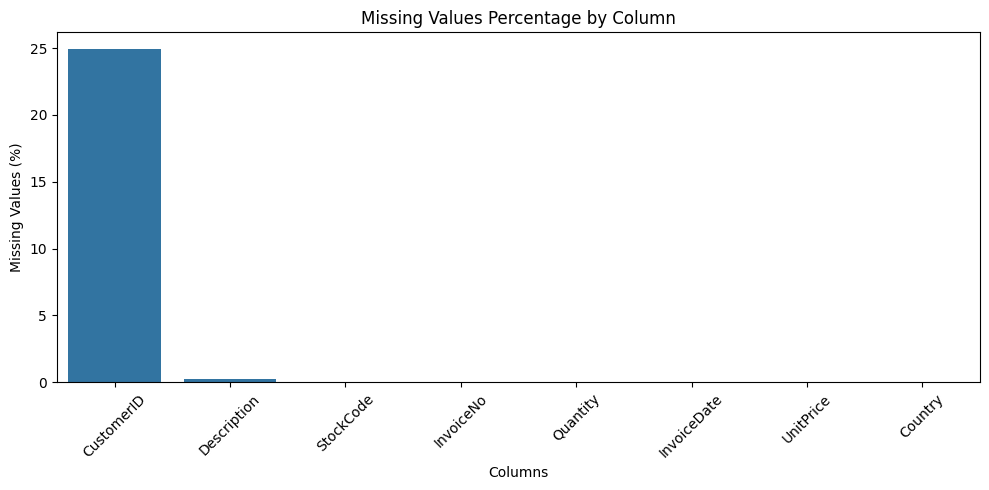

In [20]:
# Q7
missing_percent = df.isnull().mean().mul(100).sort_values(ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(x=missing_percent.index,y=missing_percent.values)

plt.title('Missing Values Percentage by Column')
plt.xlabel('Columns')
plt.ylabel('Missing Values (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

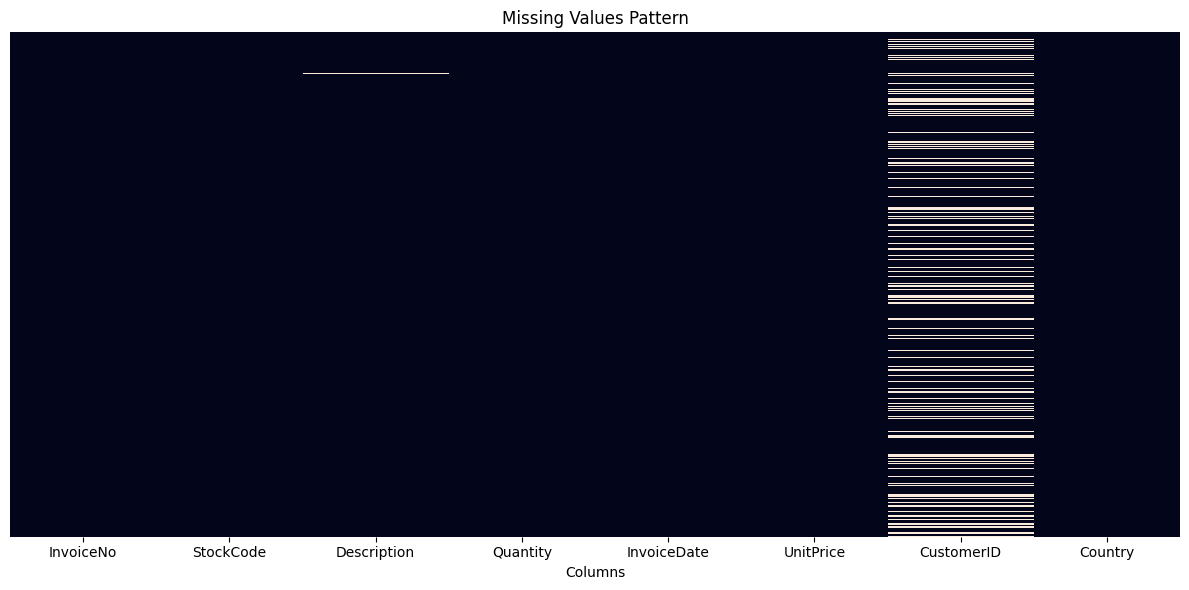

In [21]:
plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull().sample(1000, random_state=42),cbar=False,yticklabels=False)

plt.title('Missing Values Pattern')
plt.xlabel('Columns')
plt.tight_layout()
plt.show()

The missing values visualization shows that CustomerID is the most affected column, followed by Description. Missing customer identifiers may limit customer-level analysis, while missing product descriptions can affect product-level reporting. These columns require further investigation before data cleaning.

In [22]:
# Q8
print(f"number of duplicated rows: {df.duplicated().sum()}")

number of duplicated rows: 5268


In [23]:
duplicates = df[df.duplicated(keep=False)]
display(duplicates.head(10))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,12/1/2010 11:49,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,12/1/2010 11:49,2.95,17920.0,United Kingdom


In [24]:
sample = duplicates.sample(min(10, len(duplicates)),random_state=42)
sample

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
521294,580358,23498,CLASSIC BICYCLE CLIPS,1,12/2/2011 16:07,1.45,17238.0,United Kingdom
189208,553141,22907,PACK OF 20 NAPKINS PANTRY DESIGN,1,5/13/2011 13:01,0.85,15907.0,United Kingdom
388283,570423,20728,LUNCH BAG CARS BLUE,2,10/10/2011 13:38,1.65,14451.0,United Kingdom
385700,570211,23330,DECORATIVE WICKER HEART MEDIUM,1,10/9/2011 11:15,1.25,13558.0,United Kingdom
151072,549537,22860,EASTER TIN CHICKS PINK DAISY,1,4/8/2011 17:22,1.65,NaN,United Kingdom
16278,537646,22585,PACK OF 6 BIRDY GIFT TAGS,1,12/7/2010 15:39,1.25,17591.0,United Kingdom
503693,578933,21955,DOORMAT UNION JACK GUNS AND ROSES,1,11/27/2011 12:47,8.25,16923.0,United Kingdom
5465,536863,20986,BLUE CALCULATOR RULER,2,12/3/2010 11:19,1.25,17967.0,United Kingdom
188791,553061,20727,LUNCH BAG BLACK SKULL.,1,5/13/2011 11:12,1.65,17238.0,United Kingdom
201765,554323,22998,TRAVEL CARD WALLET KEEP CALM,24,5/23/2011 15:33,0.42,16729.0,United Kingdom


Fully duplicated rows represent repeated records where all column values are identical. These duplicates may result from repeated data entry or data collection issues. They should be investigated before removal to avoid losing potentially meaningful transaction records.

In [25]:
# Q9
df['InvoiceNo'].head(10)

,InvoiceNo
0,536365
1,536365
2,536365
3,536365
4,536365
5,536365
6,536365
7,536366
8,536366
9,536367


In [26]:
df['InvoiceNo'].dtype

dtype('O')

In [27]:
cancelled = df['InvoiceNo'].astype(str).str.startswith('C')
df[cancelled].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/2010 9:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/2010 9:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,12/1/2010 10:24,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,12/1/2010 10:24,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,12/1/2010 12:38,4.25,17897.0,United Kingdom


In [28]:
print(f"cancelled rows: {cancelled.sum()}")

cancelled rows: 9288


In [29]:
cancellation_share = (cancelled.sum() / len(df)) * 100
print(f"Cancellation share: {cancellation_share:.2f}%")

Cancellation share: 1.71%


In [30]:
cancelled_invoices = df.loc[cancelled, 'InvoiceNo'].nunique()
print(f"unique cancelled invoices: {cancelled_invoices}")

unique cancelled invoices: 3836


Cancellation invoices can be identified by invoice numbers starting with the letter 'C'. These records represent cancelled transactions or returned items and should be analyzed separately from regular sales. Their proportion indicates how frequently cancellation-related records appear in the dataset.

In [31]:
# Q10
zero_quantity = (df['Quantity'] == 0).sum()
negative_quantity = (df['Quantity'] < 0).sum()

print(f"zero quantities: {zero_quantity}")
print(f"negative quantities: {negative_quantity}")

zero quantities: 0
negative quantities: 10624


In [32]:
df[df['Quantity'] == 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country


In [33]:
negative_rows = df[df['Quantity'] < 0]
negative_rows.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/2010 9:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/2010 9:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,12/1/2010 10:24,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,12/1/2010 10:24,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,12/1/2010 12:38,4.25,17897.0,United Kingdom


In [34]:
negative_analysis = df[df['Quantity'] < 0].copy()
negative_analysis['Is_Cancelled'] = (negative_analysis['InvoiceNo'].astype(str).str.startswith('C'))

negative_analysis['Is_Cancelled'].value_counts()

,count
Is_Cancelled,
True,9288
False,1336


Negative quantities are not necessarily data errors. In retail transactions, they often represent returned products or cancelled orders. Invoice numbers starting with 'C' can help identify cancellation-related transactions. Therefore, negative quantities should be investigated in their business context rather than automatically removed. Zero quantities may indicate unusual or incomplete transaction records and require further inspection.

In [35]:
# Q11
zero_prices = (df['UnitPrice'] == 0).sum()
negative_prices = (df['UnitPrice'] < 0).sum()

print(f"zero prices: {zero_prices}")
print(f"negative prices: {negative_prices}")

zero prices: 2515
negative prices: 2


In [36]:
total_rows = len(df)

print(f"zero prices: {zero_prices / total_rows * 100:.2f}%")
print(f"negative prices: {negative_prices / total_rows * 100:.2f}%")

zero prices: 0.46%
negative prices: 0.00%


In [37]:
zero_price_rows = df[df['UnitPrice'] == 0]
zero_price_rows.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,12/1/2010 11:52,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,12/1/2010 14:32,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,12/1/2010 14:33,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,12/1/2010 14:33,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,12/1/2010 14:34,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,12/1/2010 14:34,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,12/1/2010 14:34,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,12/1/2010 14:35,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,12/1/2010 14:35,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,12/1/2010 16:50,0.0,NaN,United Kingdom


In [38]:
negative_price_rows = df[df['UnitPrice'] < 0]
negative_price_rows.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,8/12/2011 14:51,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,8/12/2011 14:52,-11062.06,NaN,United Kingdom


In [39]:
negative_price_rows[['InvoiceNo', 'StockCode', 'Description','Quantity', 'UnitPrice', 'CustomerID', 'Country']]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,-11062.06,NaN,United Kingdom


Zero unit prices may represent free items, promotional products, or special transactions rather than data errors. Negative unit prices are unusual and require further investigation to understand their business meaning. Therefore, neither zero nor negative values should be automatically removed without examining the associated transaction records.

In [40]:
# Q12
print(f"missing descriptions: {df['Description'].isnull().sum()}")
df[df['Description'].isnull()].head(10)

missing descriptions: 1454


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,12/1/2010 11:52,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,12/1/2010 14:32,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,12/1/2010 14:33,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,12/1/2010 14:33,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,12/1/2010 14:34,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,12/1/2010 14:34,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,12/1/2010 14:34,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,12/1/2010 14:35,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,12/1/2010 14:35,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,12/1/2010 16:50,0.0,NaN,United Kingdom


In [41]:
print(f"unique descriptions: {df['Description'].nunique()}")
print(f"repeated description values: {df['Description'].value_counts().gt(1).sum()}")

unique descriptions: 4223
repeated description values: 3915


In [42]:
df['Description'].value_counts().head(10)

,count
Description,
WHITE HANGING HEART T-LIGHT HOLDER,2369
REGENCY CAKESTAND 3 TIER,2200
JUMBO BAG RED RETROSPOT,2159
PARTY BUNTING,1727
LUNCH BAG RED RETROSPOT,1638
ASSORTED COLOUR BIRD ORNAMENT,1501
SET OF 3 CAKE TINS PANTRY DESIGN,1473
PACK OF 72 RETROSPOT CAKE CASES,1385
LUNCH BAG BLACK SKULL.,1350


In [43]:
product_descriptions = (df.groupby('StockCode')['Description'].nunique().sort_values(ascending=False))
product_descriptions.head(20)

,Description
StockCode,
20713,8
23084,7
21830,6
85175,6
21181,5
72807A,5
23131,5
23343,5
85172,5


In [44]:
multiple_descriptions = product_descriptions[product_descriptions > 1]
print(f"product codes with multiple descriptions: {len(multiple_descriptions)}")

product codes with multiple descriptions: 650


In [45]:
codes = multiple_descriptions.index[:10]
df[df['StockCode'].isin(codes)][['StockCode', 'Description']].drop_duplicates().sort_values('StockCode')

,StockCode,Description
522,20713,JUMBO BAG OWLS
380688,20713,wrongly coded-23343
403534,20713,found
414145,20713,Found
415582,20713,wrongly marked 23343
...,...,...
114535,85175,dotcom sold sets
114538,85175,wrongly sold sets
114539,85175,? sold as sets?
3278,85175,CACTI T-LIGHT CANDLES


The Description column contains repeated product names, which is expected because the same product can appear in multiple transactions. Some descriptions may also be missing. Additionally, certain StockCodes may be associated with multiple descriptions, indicating possible inconsistencies in product naming or changes in product descriptions over time.

In [46]:
# Q13
missing_customers = df['CustomerID'].isnull().sum()
missing_percentage = df['CustomerID'].isnull().mean() * 100

print(f"missing CustomerID: {missing_customers}")
print(f"missing Percentage: {missing_percentage:.2f}%")

missing CustomerID: 135080
missing Percentage: 24.93%


In [47]:
df[df['CustomerID'].isnull()].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,12/1/2010 11:52,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,12/1/2010 14:32,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,12/1/2010 14:32,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,12/1/2010 14:32,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,12/1/2010 14:32,1.66,NaN,United Kingdom
1447,536544,21790,VINTAGE SNAP CARDS,9,12/1/2010 14:32,1.66,NaN,United Kingdom
1448,536544,21791,VINTAGE HEADS AND TAILS CARD GAME,2,12/1/2010 14:32,2.51,NaN,United Kingdom
1449,536544,21801,CHRISTMAS TREE DECORATION WITH BELL,10,12/1/2010 14:32,0.43,NaN,United Kingdom
1450,536544,21802,CHRISTMAS TREE HEART DECORATION,9,12/1/2010 14:32,0.43,NaN,United Kingdom
1451,536544,21803,CHRISTMAS TREE STAR DECORATION,11,12/1/2010 14:32,0.43,NaN,United Kingdom


In [48]:
print("number of countries:", df['Country'].nunique())

number of countries: 38


In [49]:
country_counts = df['Country'].value_counts()
display(country_counts)

,count
Country,
United Kingdom,495478
Germany,9495
France,8557
EIRE,8196
Spain,2533
Netherlands,2371
Belgium,2069
Switzerland,2002
Portugal,1519


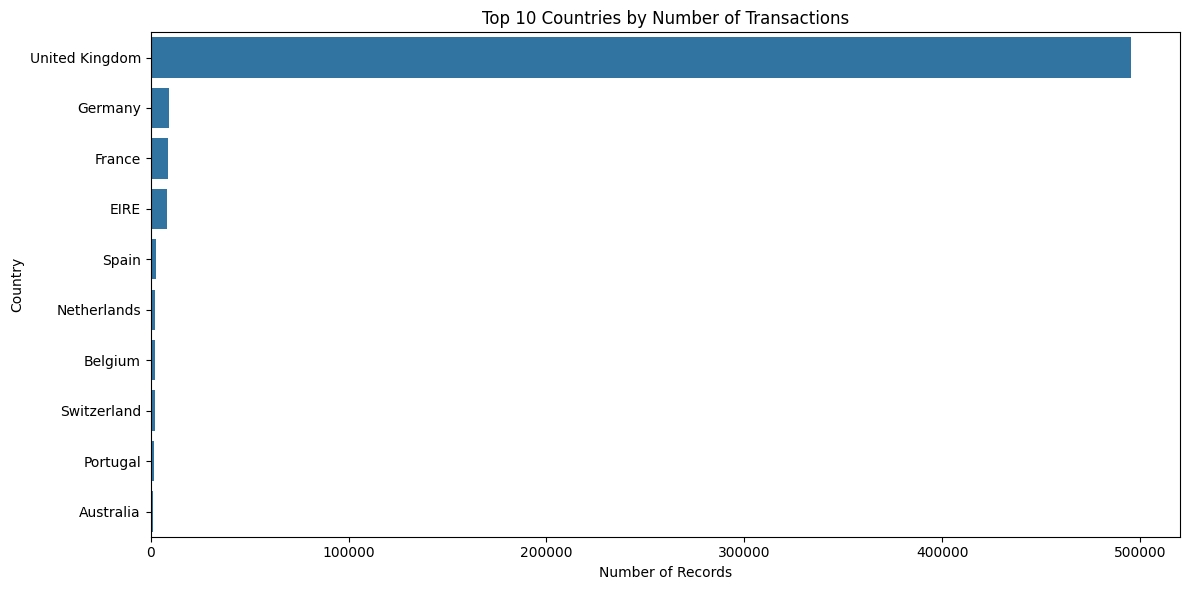

In [50]:
plt.figure(figsize=(12, 6))
sns.barplot(x=country_counts.head(10).values,y=country_counts.head(10).index)

plt.title('Top 10 Countries by Number of Transactions')
plt.xlabel('Number of Records')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

Some transactions have missing CustomerID values, which limits customer-level analysis. However, these records can still be used for product-level, country-level, and time-based sales analysis.

Country distribution shows that the dataset contains transactions from multiple countries, allowing geographic sales comparisons. CustomerID is essential for customer segmentation, repeat purchase analysis, and customer lifetime value calculations, but it is not required for general sales and product analysis.

---

# Part 3 — Data Cleaning & Feature Engineering (Questions 14–18)

### Q14. Define a cleaning strategy
Before changing the data, write a short plan. Explain how you will handle:
- Missing customer IDs and descriptions.
- Exact duplicate rows.
- Cancellation invoices.
- Negative quantities and zero/negative prices.
- Incorrect data types.

Do not delete returns or cancellations without explaining the analytical purpose.

### Q15. Apply cleaning steps
Create a separate DataFrame named `clean_df`. Apply your chosen cleaning strategy and document how many rows were removed or changed at each step.

### Q16. Convert data types
Ensure `InvoiceDate` is datetime and `CustomerID` is handled consistently. Convert other fields to appropriate types where justified.

### Q17. Create transaction revenue
Create a `Revenue` column using `Quantity * UnitPrice`. Explain how this calculation behaves for negative quantities and cancellation records.

### Q18. Create date features
Create `Year`, `Month`, `MonthName`, `DayName`, and `Hour` from `InvoiceDate`. Keep a chronological month order for later charts.

In [51]:
# Q14–Q18: Write your cleaning and feature-engineering code here.

**Missing CustomerIDs and Descriptions**
CustomerID: I will keep records with missing CustomerIDs because they can still be used for revenue, product, country, and time-based analysis. They will only be excluded from customer-level analysis.
Description: I will investigate missing descriptions using StockCode. If a reliable product description can be identified, I may fill the missing values. Otherwise, I will keep them missing or label them as "Unknown" when needed for reporting.

**Exact Duplicate Rows** I will remove fully duplicated rows after investigating them because exact duplicates may represent repeated records that could inflate sales and transaction counts.
I will keep the original dataset unchanged and perform cleaning on a separate copy.

**Cancellation Invoices** I will identify cancellation invoices using InvoiceNo values starting with C.

I will not automatically delete cancellation records. Instead, I will separate regular sales from cancellations to support different analytical purposes:
- Gross Sales: Analyze regular sales transactions.
- Returns and Cancellations: Analyze cancelled or returned transactions separately.
- Net Sales: Account for returns when calculating net sales.

**Negative Quantities and Zero/Negative Prices**

- Negative Quantity: I will preserve negative quantities because they may represent returned products or cancelled transactions.
- Zero UnitPrice: I will investigate these records to identify free products, promotional items, or possible data issues.
- Negative UnitPrice: I will inspect these unusual records individually before deciding whether they should be excluded from revenue calculations.
I will avoid removing these records without understanding their business meaning.

The cleaning process will focus on improving data quality while preserving meaningful business information. Returns and cancellations will be retained for financial and operational analysis, while separate filtered datasets will be created when analyzing completed sales. Missing customer identifiers will not prevent transactions from being used in general sales analysis.

In [52]:
# Q15
clean_df = df.copy()
original_rows = len(clean_df)
print(f"original rows: {original_rows}")

original rows: 541909


In [53]:
before = len(clean_df)
clean_df = clean_df.drop_duplicates()
removed_duplicates = before - len(clean_df)

print(f"removed duplicate rows: {removed_duplicates}")
print(f"remaining rows: {len(clean_df)}")

removed duplicate rows: 5268
remaining rows: 536641


In [54]:
missing_customer_ids = clean_df['CustomerID'].isnull().sum()
print(f"missing CustomerIDs retained: {missing_customer_ids}")

missing CustomerIDs retained: 135037


In [55]:
before_missing = clean_df['Description'].isnull().sum()
description_mapping = (clean_df.dropna(subset=['Description']).groupby('StockCode')['Description'].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else None))
clean_df['Description'] = clean_df['Description'].fillna(clean_df['StockCode'].map(description_mapping))
filled_descriptions = (before_missing - clean_df['Description'].isnull().sum())

print(f"filled descriptions: {filled_descriptions}")
print(f"remaining missing descriptions: {clean_df['Description'].isnull().sum()}")

filled descriptions: 1342
remaining missing descriptions: 112


In [56]:
clean_df['Is_Cancelled'] = (clean_df['InvoiceNo'].astype(str).str.startswith('C'))
print(f"cancellation rows retained: {clean_df['Is_Cancelled'].sum()}")

cancellation rows retained: 9251


In [57]:
sales_df = clean_df[~clean_df['Is_Cancelled']].copy()

In [58]:
clean_df['Is_Return'] = clean_df['Quantity'] < 0
clean_df['Is_Zero_Price'] = clean_df['UnitPrice'] == 0
clean_df['Is_Negative_Price'] = clean_df['UnitPrice'] < 0

In [59]:
clean_df['InvoiceNo'] = clean_df['InvoiceNo'].astype('string')
clean_df['StockCode'] = clean_df['StockCode'].astype('string')
clean_df['Description'] = clean_df['Description'].astype('string')
clean_df['InvoiceDate'] = pd.to_datetime(clean_df['InvoiceDate'],errors='coerce')
clean_df['CustomerID'] = clean_df['CustomerID'].astype('Int64')
clean_df['Country'] = clean_df['Country'].astype('category')

In [60]:
cleaning_log = pd.DataFrame({
    'Step': [
        'Original Dataset',
        'Remove Exact Duplicates',
        'Fill Missing Descriptions',
        'Retain Missing CustomerIDs',
        'Retain Cancellations',
        'Retain Negative Quantities',
        'Retain Unusual Prices',
        'Data Type Conversion'
    ],
    'Rows_Removed': [
        0,
        removed_duplicates,
        0,
        0,
        0,
        0,
        0,
        0
    ],
    'Rows_Changed': [
        0,
        0,
        filled_descriptions,
        0,
        0,
        0,
        0,
        0
    ]
})

cleaning_log

,Step,Rows_Removed,Rows_Changed
0,Original Dataset,0,0
1,Remove Exact Duplicates,5268,0
2,Fill Missing Descriptions,0,1342
3,Retain Missing CustomerIDs,0,0
4,Retain Cancellations,0,0
5,Retain Negative Quantities,0,0
6,Retain Unusual Prices,0,0
7,Data Type Conversion,0,0


In [61]:
print(f"original shape: {df.shape}")
print(f"cleaned shape: {clean_df.shape}")
print(f"remaining duplicates: {clean_df.duplicated().sum()}")
print(f"missing values: {clean_df.isnull().sum()}")
print(f"data types: {clean_df.dtypes}")

original shape: (541909, 8)
cleaned shape: (536641, 12)
remaining duplicates: 0
missing values: InvoiceNo                 0
StockCode                 0
Description             112
Quantity                  0
InvoiceDate               0
UnitPrice                 0
CustomerID           135037
Country                   0
Is_Cancelled              0
Is_Return                 0
Is_Zero_Price             0
Is_Negative_Price         0
dtype: int64
data types: InvoiceNo            string[python]
StockCode            string[python]
Description          string[python]
Quantity                      int64
InvoiceDate          datetime64[ns]
UnitPrice                   float64
CustomerID                    Int64
Country                    category
Is_Cancelled                   bool
Is_Return                      bool
Is_Zero_Price                  bool
Is_Negative_Price              bool
dtype: object


In [62]:
# Q16
clean_df.dtypes

,0
InvoiceNo,string[python]
StockCode,string[python]
Description,string[python]
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,Int64
Country,category
Is_Cancelled,bool
Is_Return,bool


In [63]:
clean_df['InvoiceDate'] = pd.to_datetime(clean_df['InvoiceDate'],errors='coerce')

In [64]:
clean_df['CustomerID'] = clean_df['CustomerID'].astype('Int64')

In [65]:
clean_df['InvoiceNo'] = clean_df['InvoiceNo'].astype('string')
clean_df['StockCode'] = clean_df['StockCode'].astype('string')
clean_df['Description'] = clean_df['Description'].astype('string')
clean_df['Country'] = clean_df['Country'].astype('category')

In [66]:
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 536641 entries, 0 to 541908
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   InvoiceNo          536641 non-null  string        
 1   StockCode          536641 non-null  string        
 2   Description        536529 non-null  string        
 3   Quantity           536641 non-null  int64         
 4   InvoiceDate        536641 non-null  datetime64[ns]
 5   UnitPrice          536641 non-null  float64       
 6   CustomerID         401604 non-null  Int64         
 7   Country            536641 non-null  category      
 8   Is_Cancelled       536641 non-null  bool          
 9   Is_Return          536641 non-null  bool          
 10  Is_Zero_Price      536641 non-null  bool          
 11  Is_Negative_Price  536641 non-null  bool          
dtypes: Int64(1), bool(4), category(1), datetime64[ns](1), float64(1), int64(1), string(3)
memory usage: 35.8 

In [67]:
display(
    pd.DataFrame({
        'Column': clean_df.columns,
        'Data_Type': clean_df.dtypes.astype(str).values
    })
)

,Column,Data_Type
0,InvoiceNo,string
1,StockCode,string
2,Description,string
3,Quantity,int64
4,InvoiceDate,datetime64[ns]
5,UnitPrice,float64
6,CustomerID,Int64
7,Country,category
8,Is_Cancelled,bool
9,Is_Return,bool


In [68]:
print(f"invalid dates: {clean_df['InvoiceDate'].isna().sum()}")

invalid dates: 0


In [69]:
# Q17
clean_df['Revenue'] = clean_df['Quantity'] * clean_df['UnitPrice']
clean_df.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Is_Cancelled,Is_Return,Is_Zero_Price,Is_Negative_Price,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,False,False,False,False,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,False,False,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,False,False,False,False,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,False,False,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,False,False,20.34
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850,United Kingdom,False,False,False,False,15.30
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850,United Kingdom,False,False,False,False,25.50
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850,United Kingdom,False,False,False,False,11.10
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850,United Kingdom,False,False,False,False,11.10
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047,United Kingdom,False,False,False,False,54.08


In [70]:
clean_df['Revenue'].describe()

,Revenue
count,536641.000000
mean,18.123861
std,380.656263
min,-168469.600000
25%,3.750000
50%,9.870000
75%,17.400000
max,168469.600000


In [71]:
print(f"negative Revenue: {(clean_df['Revenue'] < 0).sum()}")
print(f"zero Revenue: {(clean_df['Revenue'] == 0).sum()}")

negative Revenue: 9253
zero Revenue: 2510


In [72]:
clean_df.groupby('Is_Cancelled')['Revenue'].agg(['count', 'sum', 'mean'])

,count,sum,mean
Is_Cancelled,,,
False,527390,1.061999e+07,20.136875
True,9251,-8.939797e+05,-96.636010


In [73]:
gross_sales = clean_df.loc[~clean_df['Is_Cancelled'] & (clean_df['Revenue'] > 0),'Revenue'].sum()
cancellation_revenue = clean_df.loc[clean_df['Is_Cancelled'],'Revenue'].sum()
net_revenue = clean_df['Revenue'].sum()

print(f"gross sales: {gross_sales:,.2f}")
print(f"cancellation revenue: {cancellation_revenue:,.2f}")
print(f"net revenue: {net_revenue:,.2f}")

gross sales: 10,642,110.80
cancellation revenue: -893,979.73
net revenue: 9,726,006.95


A new Revenue column was created by multiplying Quantity by UnitPrice. Positive quantities generate positive revenue, while negative quantities generate negative revenue, which may represent returned products or refunds. Cancellation invoices commonly contain negative quantities and therefore contribute negative revenue. These records are retained because they are important for calculating net revenue and understanding return activity.

In [74]:
# Q18
clean_df['Year'] = clean_df['InvoiceDate'].dt.year
clean_df['Month'] = clean_df['InvoiceDate'].dt.month
clean_df['MonthName'] = clean_df['InvoiceDate'].dt.month_name()
clean_df['DayName'] = clean_df['InvoiceDate'].dt.day_name()
clean_df['Hour'] = clean_df['InvoiceDate'].dt.hour

In [75]:
import calendar

month_order = list(calendar.month_name)[1:]
clean_df['MonthName'] = pd.Categorical(clean_df['MonthName'],categories=month_order,ordered=True)

In [76]:
clean_df[['InvoiceDate', 'Year', 'Month','MonthName', 'DayName', 'Hour']].head(10)

,InvoiceDate,Year,Month,MonthName,DayName,Hour
0,2010-12-01 08:26:00,2010,12,December,Wednesday,8
1,2010-12-01 08:26:00,2010,12,December,Wednesday,8
2,2010-12-01 08:26:00,2010,12,December,Wednesday,8
3,2010-12-01 08:26:00,2010,12,December,Wednesday,8
4,2010-12-01 08:26:00,2010,12,December,Wednesday,8
5,2010-12-01 08:26:00,2010,12,December,Wednesday,8
6,2010-12-01 08:26:00,2010,12,December,Wednesday,8
7,2010-12-01 08:28:00,2010,12,December,Wednesday,8
8,2010-12-01 08:28:00,2010,12,December,Wednesday,8
9,2010-12-01 08:34:00,2010,12,December,Wednesday,8


In [77]:
clean_df['MonthName'].value_counts().sort_index()

,count
MonthName,
January,34900
February,27479
March,36439
April,29701
May,36782
June,36609
July,39267
August,35064
September,49861


New date-based features were extracted from InvoiceDate, including Year, Month, MonthName, DayName, and Hour. These features will support time-based sales analysis, such as monthly revenue trends, weekday performance, and hourly transaction patterns. MonthName was converted into an ordered categorical variable to preserve chronological order in future visualizations.

---

# Part 4 — Pandas Business Analysis (Questions 19–24)

### Q19. Top products by quantity
Find the 10 products with the highest total quantity sold. Exclude or separately report returns so that sales and returns are not mixed.

### Q20. Top products by revenue
Find the 10 products with the highest total revenue. Compare the ranking with Q19. Are the same products at the top?

### Q21. Country performance
Calculate total revenue, number of invoices, and average invoice value for each country. Rank countries by revenue and compare the United Kingdom with other countries.

### Q22. Monthly revenue trend
Aggregate revenue by month and year. Which month has the highest revenue? Which month has the lowest? Use a chronological index.

### Q23. Customer analysis
Calculate total spend, number of invoices, and average spend per customer. Identify the top 10 customers by total spend. State how you handled missing CustomerID values.

### Q24. Invoice-level analysis
Group records by `InvoiceNo` to calculate invoice value, number of distinct products, and total quantity. Identify the largest invoices and investigate whether cancellations affect the ranking.

In [78]:
# Q19–Q24: Write your Pandas analysis code here.

In [79]:
# Q19
sales = clean_df[clean_df['Quantity'] > 0].copy()
returns = clean_df[clean_df['Quantity'] < 0].copy()

In [80]:
top_products = (sales.groupby(['StockCode', 'Description'])['Quantity'].sum().sort_values(ascending=False).head(10).reset_index())
top_products

,StockCode,Description,Quantity
0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033
2,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
3,85099B,JUMBO BAG RED RETROSPOT,48375
4,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37584
5,22197,POPCORN HOLDER,36749
6,21212,PACK OF 72 RETROSPOT CAKE CASES,36396
7,84879,ASSORTED COLOUR BIRD ORNAMENT,36362
8,23084,RABBIT NIGHT LIGHT,31555
9,22492,MINI PAINT SET VINTAGE,26633


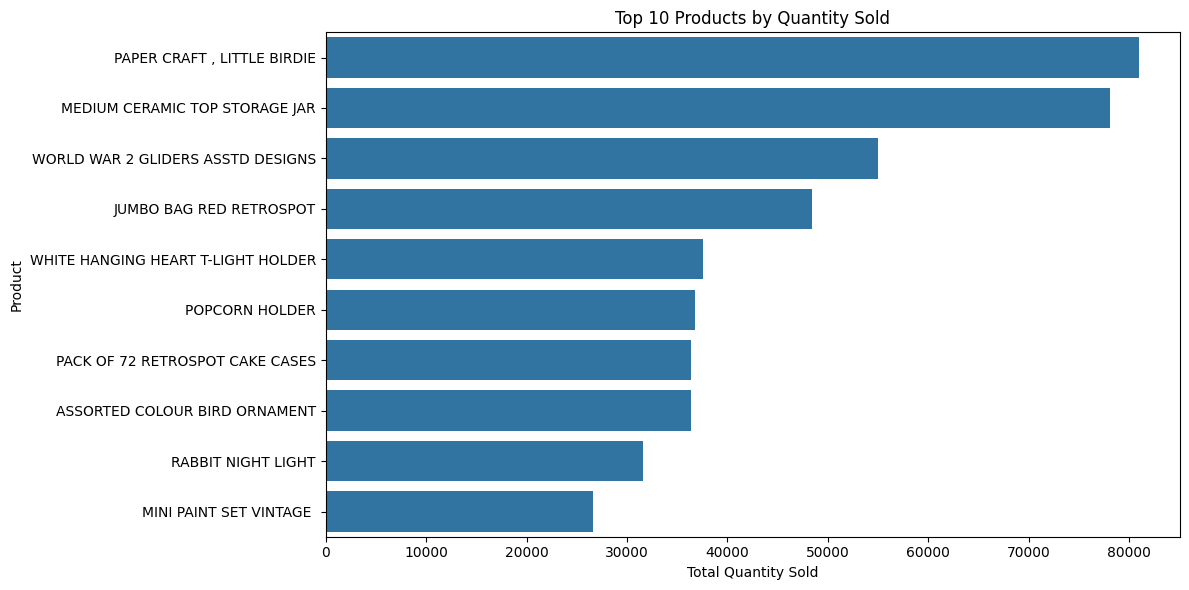

In [81]:
plt.figure(figsize=(12, 6))
sns.barplot(data=top_products,x='Quantity',y='Description')

plt.title('Top 10 Products by Quantity Sold')
plt.xlabel('Total Quantity Sold')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

In [82]:
top_returns = (returns.groupby(['StockCode', 'Description'])['Quantity'].sum().abs().sort_values(ascending=False).head(10).reset_index(name='Returned Quantity'))
top_returns

,StockCode,Description,Returned Quantity
0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,74494
2,23005,printing smudges/thrown away,19200
3,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9376
4,23003,Printing smudges/thrown away,9058
5,72140F,throw away,5368
6,79323W,"Unsaleable, destroyed.",4830
7,M,Manual,4066
8,16045,POPART WOODEN PENCILS ASST,3667
9,16259,PIECE OF CAMO STATIONERY SET,3275


- The top-selling products represent the items with the highest total positive quantities.
- Returns were analyzed separately to avoid mixing returned items with sold quantities.
- High sales volume does not necessarily indicate high revenue, because products have different unit prices.

In [83]:
# Q20
sales = clean_df[clean_df['Quantity'] > 0].copy()
top_revenue = (sales.groupby('StockCode')['Revenue'].sum().sort_values(ascending=False).head(10).reset_index())

In [84]:
product_names = (clean_df.dropna(subset=['Description']).groupby('StockCode')['Description'].agg(lambda s: s.mode().iat[0] if not s.mode().empty else s.iloc[0]))
top_revenue['Description'] = top_revenue['StockCode'].map(product_names)
top_revenue = top_revenue[['StockCode', 'Description', 'Revenue']]
top_revenue

,StockCode,Description,Revenue
0,DOT,DOTCOM POSTAGE,206248.77
1,22423,REGENCY CAKESTAND 3 TIER,174156.54
2,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104462.75
4,47566,PARTY BUNTING,99445.23
5,85099B,JUMBO BAG RED RETROSPOT,94159.81
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
7,POST,POSTAGE,78101.88
8,M,Manual,77750.27
9,23084,RABBIT NIGHT LIGHT,66870.03


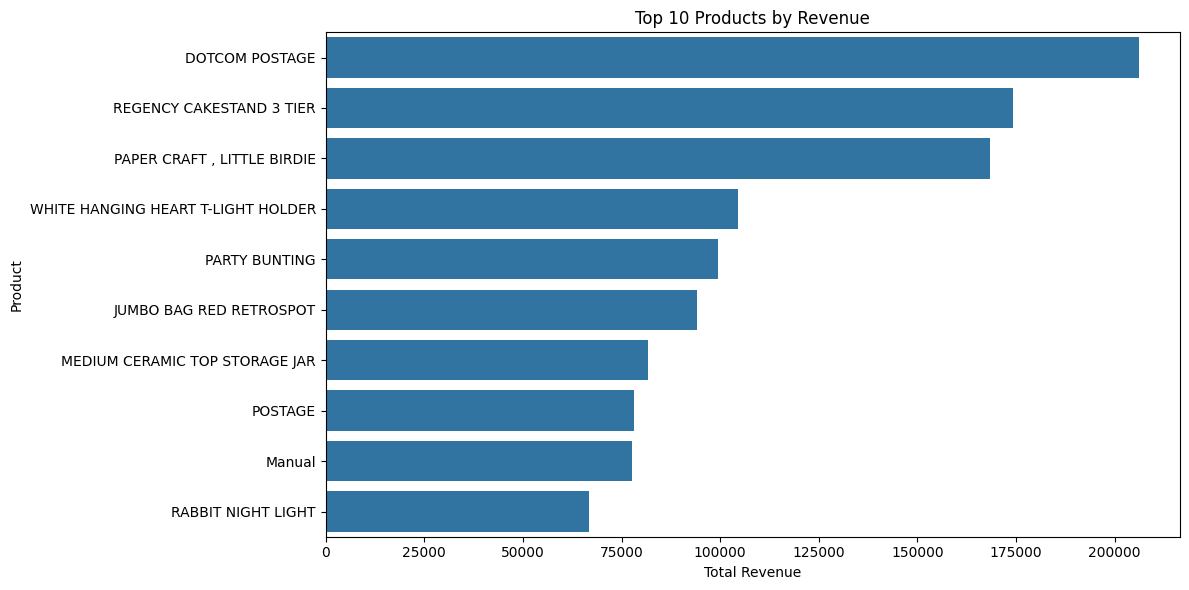

In [85]:
plt.figure(figsize=(12, 6))
sns.barplot(data=top_revenue,x='Revenue',y='Description')

plt.title('Top 10 Products by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

In [86]:
top_products = set(top_products['StockCode'])
top_revenue = set(top_revenue['StockCode'])

common_products = top_products.intersection(top_revenue)

print("Common Products:", len(common_products))
print("Products appearing in both rankings:")
print(common_products)

Common Products: 5
Products appearing in both rankings:
{'23166', '23843', '85099B', '23084', '85123A'}


The top 10 products by revenue were identified by aggregating the revenue generated by each product. The results were compared with the top 10 products by quantity sold from Q19.

This comparison helps determine whether the most frequently purchased products also generate the highest revenue. Differences between the two rankings may indicate the impact of product pricing on overall revenue.

In [87]:
# Q21
sales = clean_df[clean_df['Quantity'] > 0].copy()

In [88]:
invoice_totals = (sales.groupby(['Country', 'InvoiceNo'])['Revenue'].sum().reset_index(name='InvoiceValue'))

/tmp/ipykernel_9766/336952254.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  invoice_totals = (sales.groupby(['Country', 'InvoiceNo'])['Revenue'].sum().reset_index(name='InvoiceValue'))


In [89]:
country_performance = (
    invoice_totals.groupby('Country')
    .agg(
        Total_Revenue=('InvoiceValue', 'sum'),
        Number_of_Invoices=('InvoiceNo', 'nunique'),
        Average_Invoice_Value=('InvoiceValue', 'mean')
    )
    .sort_values('Total_Revenue', ascending=False)
    .reset_index()
)

/tmp/ipykernel_9766/3710260457.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  invoice_totals.groupby('Country')


In [90]:
country_performance

,Country,Total_Revenue,Number_of_Invoices,Average_Invoice_Value
0,United Kingdom,8979619.974,20728,433.212079
1,Netherlands,285446.340,20728,13.771051
2,EIRE,283140.520,20728,13.659809
3,Germany,228678.400,20728,11.032343
4,France,209625.370,20728,10.113150
5,Australia,138453.810,20728,6.679555
6,Spain,61558.560,20728,2.969826
7,Switzerland,57067.600,20728,2.753165
8,Belgium,41196.340,20728,1.987473
9,Sweden,38367.830,20728,1.851015


In [91]:
country_performance['Revenue_Rank'] = (country_performance['Total_Revenue'].rank(method='dense', ascending=False).astype(int))
country_performance

,Country,Total_Revenue,Number_of_Invoices,Average_Invoice_Value,Revenue_Rank
0,United Kingdom,8979619.974,20728,433.212079,1
1,Netherlands,285446.340,20728,13.771051,2
2,EIRE,283140.520,20728,13.659809,3
3,Germany,228678.400,20728,11.032343,4
4,France,209625.370,20728,10.113150,5
5,Australia,138453.810,20728,6.679555,6
6,Spain,61558.560,20728,2.969826,7
7,Switzerland,57067.600,20728,2.753165,8
8,Belgium,41196.340,20728,1.987473,9
9,Sweden,38367.830,20728,1.851015,10


In [92]:
uk_performance = country_performance[country_performance['Country'] == 'United Kingdom']
uk_performance

,Country,Total_Revenue,Number_of_Invoices,Average_Invoice_Value,Revenue_Rank
0,United Kingdom,8979619.974,20728,433.212079,1


In [93]:
other_countries = country_performance[country_performance['Country'] != 'United Kingdom']
uk_performance

,Country,Total_Revenue,Number_of_Invoices,Average_Invoice_Value,Revenue_Rank
0,United Kingdom,8979619.974,20728,433.212079,1


In [94]:
print(f"average Revenue of Other Countries: {other_countries['Total_Revenue'].mean()}")
print(f"average Invoices of Other Countries: {other_countries['Number_of_Invoices'].mean()}")
print(f"average Invoice Value of Other Countries: {other_countries['Average_Invoice_Value'].mean()}")

average Revenue of Other Countries: 44334.2354054054
average Invoices of Other Countries: 20728.0
average Invoice Value of Other Countries: 2.138857362283163


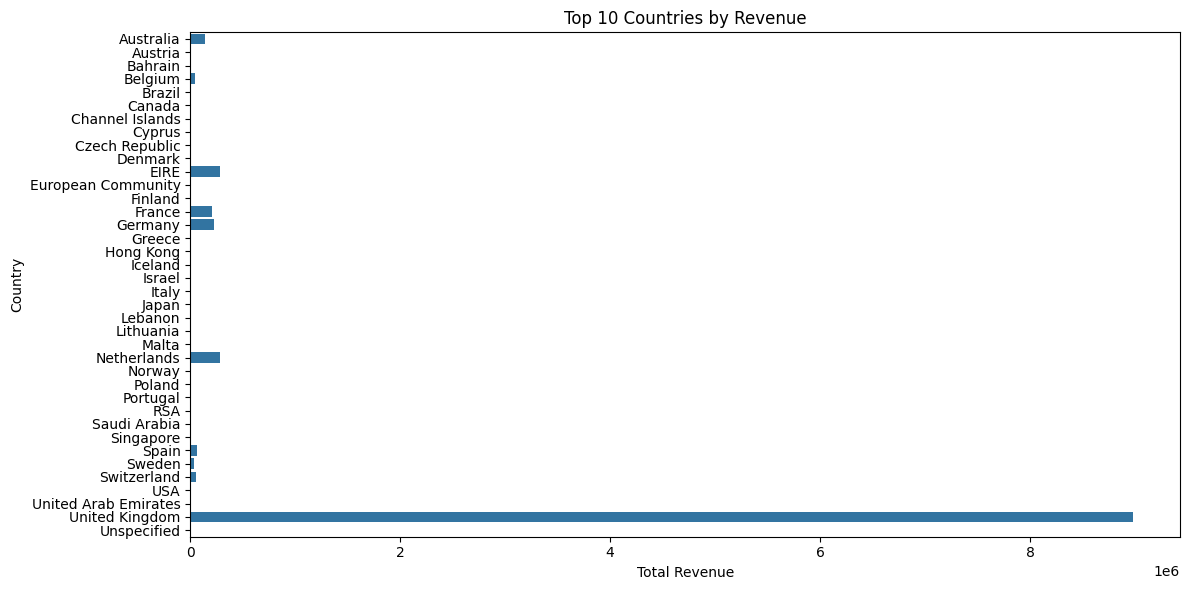

In [95]:
top_countries = country_performance.head(10)
plt.figure(figsize=(12, 6))
sns.barplot(data=top_countries,x='Total_Revenue',y='Country')

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

Country performance was evaluated using total revenue, number of unique invoices, and average invoice value. Countries were ranked based on total revenue, and the United Kingdom was compared with other countries.

This analysis helps identify the strongest markets, understand differences in transaction volume, and determine whether revenue is driven mainly by the number of invoices or by higher average invoice values.

In [96]:
# Q22
monthly_revenue = (clean_df.groupby(['Year', 'Month'])['Revenue'].sum().reset_index().sort_values(['Year', 'Month']))
monthly_revenue

,Year,Month,Revenue
0,2010,12,746723.610
1,2011,1,558448.560
2,2011,2,497026.410
3,2011,3,682013.980
4,2011,4,492367.841
5,2011,5,722094.100
6,2011,6,689977.230
7,2011,7,680156.991
8,2011,8,681386.460
9,2011,9,1017596.682


In [97]:
monthly_revenue['Date'] = pd.to_datetime(monthly_revenue['Year'].astype(str) + '-' + monthly_revenue['Month'].astype(str) + '-01')
monthly_revenue = monthly_revenue.sort_values('Date')
monthly_revenue

,Year,Month,Revenue,Date
0,2010,12,746723.610,2010-12-01
1,2011,1,558448.560,2011-01-01
2,2011,2,497026.410,2011-02-01
3,2011,3,682013.980,2011-03-01
4,2011,4,492367.841,2011-04-01
5,2011,5,722094.100,2011-05-01
6,2011,6,689977.230,2011-06-01
7,2011,7,680156.991,2011-07-01
8,2011,8,681386.460,2011-08-01
9,2011,9,1017596.682,2011-09-01


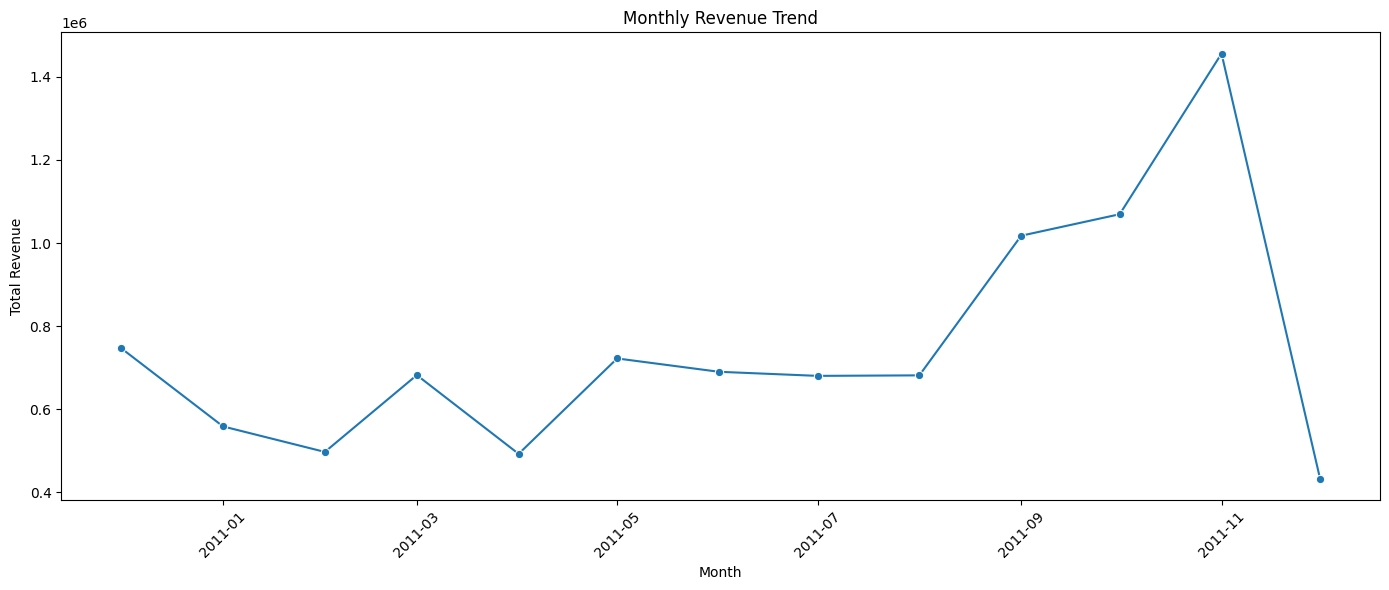

In [98]:
plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_revenue,x='Date',y='Revenue',marker='o')

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [99]:
highest_month = monthly_revenue.loc[monthly_revenue['Revenue'].idxmax()]
lowest_month = monthly_revenue.loc[monthly_revenue['Revenue'].idxmin()]

print(f"highest Revenue Month: {highest_month[['Date', 'Revenue']]}")
print(f"lowest Revenue Month: {lowest_month[['Date', 'Revenue']]}")

highest Revenue Month: Date       2011-11-01 00:00:00
Revenue              1456145.8
Name: 11, dtype: object
lowest Revenue Month: Date       2011-12-01 00:00:00
Revenue              432701.06
Name: 12, dtype: object


Monthly revenue was aggregated by year and month to examine the overall revenue trend over time. A chronological date index was created to ensure that the months were displayed in the correct order.

The highest and lowest revenue months were identified to highlight potential seasonal patterns and fluctuations in business performance.

In [100]:
# Q23
customer_df = clean_df.dropna(subset=['CustomerID']).copy()

In [101]:
customer_analysis = (customer_df.groupby('CustomerID').agg(Total_Spend=('Revenue', 'sum'),Number_of_Invoices=('InvoiceNo', 'nunique')).reset_index())
customer_analysis['Average_Spend_Per_Invoice'] = (customer_analysis['Total_Spend'] / customer_analysis['Number_of_Invoices'])
customer_analysis.head(10)

,CustomerID,Total_Spend,Number_of_Invoices,Average_Spend_Per_Invoice
0,12346,0.00,2,0.000000
1,12347,4310.00,7,615.714286
2,12348,1797.24,4,449.310000
3,12349,1757.55,1,1757.550000
4,12350,334.40,1,334.400000
5,12352,1545.41,11,140.491818
6,12353,89.00,1,89.000000
7,12354,1079.40,1,1079.400000
8,12355,459.40,1,459.400000
9,12356,2811.43,3,937.143333


In [102]:
top_customers = (customer_analysis.sort_values('Total_Spend', ascending=False).head(10))
top_customers

,CustomerID,Total_Spend,Number_of_Invoices,Average_Spend_Per_Invoice
1703,14646,279489.02,77,3629.727532
4233,18102,256438.49,62,4136.104677
3758,17450,187322.17,55,3405.857636
1895,14911,132458.73,248,534.107782
55,12415,123725.45,26,4758.671154
1345,14156,113214.59,66,1715.372576
3801,17511,88125.38,46,1915.769130
3202,16684,65892.08,31,2125.550968
1005,13694,62690.54,60,1044.842333
2192,15311,59284.19,118,502.408390


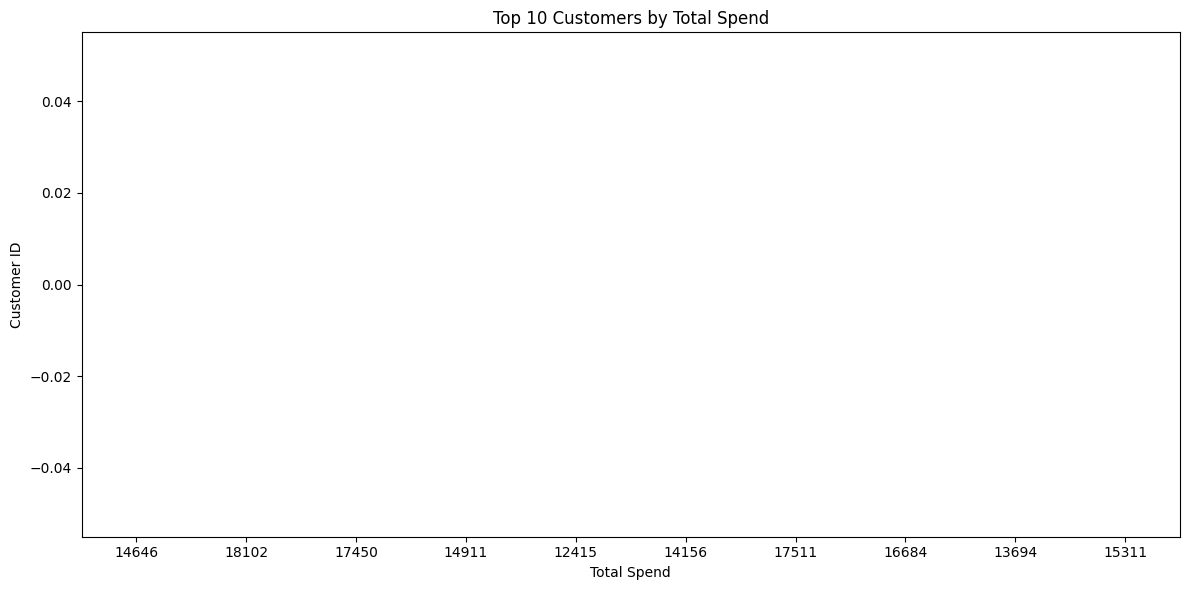

In [103]:
plt.figure(figsize=(12, 6))
sns.barplot(data=top_customers,x='Total_Spend',y='CustomerID',order=top_customers.sort_values('Total_Spend', ascending=False)['CustomerID'])

plt.title('Top 10 Customers by Total Spend')
plt.xlabel('Total Spend')
plt.ylabel('Customer ID')
plt.tight_layout()
plt.show()

Customer performance was analyzed using total spend, number of unique invoices, and average spend per invoice. The top 10 customers were identified based on their total spend.

Records with missing CustomerID values were excluded from customer-level analysis because they could not be reliably associated with specific customers. However, these records were retained in the main dataset for other analyses.

In [104]:
# Q24
invoice_analysis = (clean_df.groupby('InvoiceNo').agg(Invoice_Value=('Revenue', 'sum'),Distinct_Products=('StockCode', 'nunique'),Total_Quantity=('Quantity', 'sum'),Is_Cancelled=('Is_Cancelled', 'max')).reset_index())
invoice_analysis.head()

,InvoiceNo,Invoice_Value,Distinct_Products,Total_Quantity,Is_Cancelled
0,536365,139.12,7,40,False
1,536366,22.20,2,12,False
2,536367,278.73,12,83,False
3,536368,70.05,4,15,False
4,536369,17.85,1,3,False


In [105]:
largest_invoices = (invoice_analysis.sort_values('Invoice_Value', ascending=False).head(10))
largest_invoices

,InvoiceNo,Invoice_Value,Distinct_Products,Total_Quantity,Is_Cancelled
22025,581483,168469.60,1,80995,False
2303,541431,77183.60,1,74215,False
18776,574941,52940.94,101,14149,False
19468,576365,50653.91,99,13956,False
9741,556444,38970.00,1,60,False
15046,567423,31698.16,12,12572,False
9951,556917,22775.93,138,15049,False
17393,572209,22206.00,7,1920,False
15038,567381,22104.80,12,6760,False
13240,563614,21880.44,97,12196,False


In [106]:
invoice_analysis['Is_Cancelled'].value_counts()

,count
Is_Cancelled,
False,22064
True,3836


In [107]:
largest_regular_invoices = (invoice_analysis[invoice_analysis['Is_Cancelled'] == False].sort_values('Invoice_Value', ascending=False).head(10))
largest_regular_invoices

,InvoiceNo,Invoice_Value,Distinct_Products,Total_Quantity,Is_Cancelled
22025,581483,168469.60,1,80995,False
2303,541431,77183.60,1,74215,False
18776,574941,52940.94,101,14149,False
19468,576365,50653.91,99,13956,False
9741,556444,38970.00,1,60,False
15046,567423,31698.16,12,12572,False
9951,556917,22775.93,138,15049,False
17393,572209,22206.00,7,1920,False
15038,567381,22104.80,12,6760,False
13240,563614,21880.44,97,12196,False


In [108]:
largest_cancelled_invoices = (invoice_analysis[invoice_analysis['Is_Cancelled'] == True].sort_values('Invoice_Value', ascending=False).head(10))
largest_cancelled_invoices

,InvoiceNo,Invoice_Value,Distinct_Products,Total_Quantity,Is_Cancelled
24275,C561016,-0.39,1,-1,True
25065,C570331,-0.39,1,-1,True
22756,C543780,-0.42,1,-1,True
22949,C545847,-0.42,1,-1,True
24165,C559830,-0.48,1,-1,True
25292,C573172,-0.50,1,-1,True
23774,C555354,-0.65,1,-1,True
24091,C558903,-0.65,1,-1,True
22904,C545511,-0.65,1,-1,True
24465,C563249,-0.72,1,-1,True


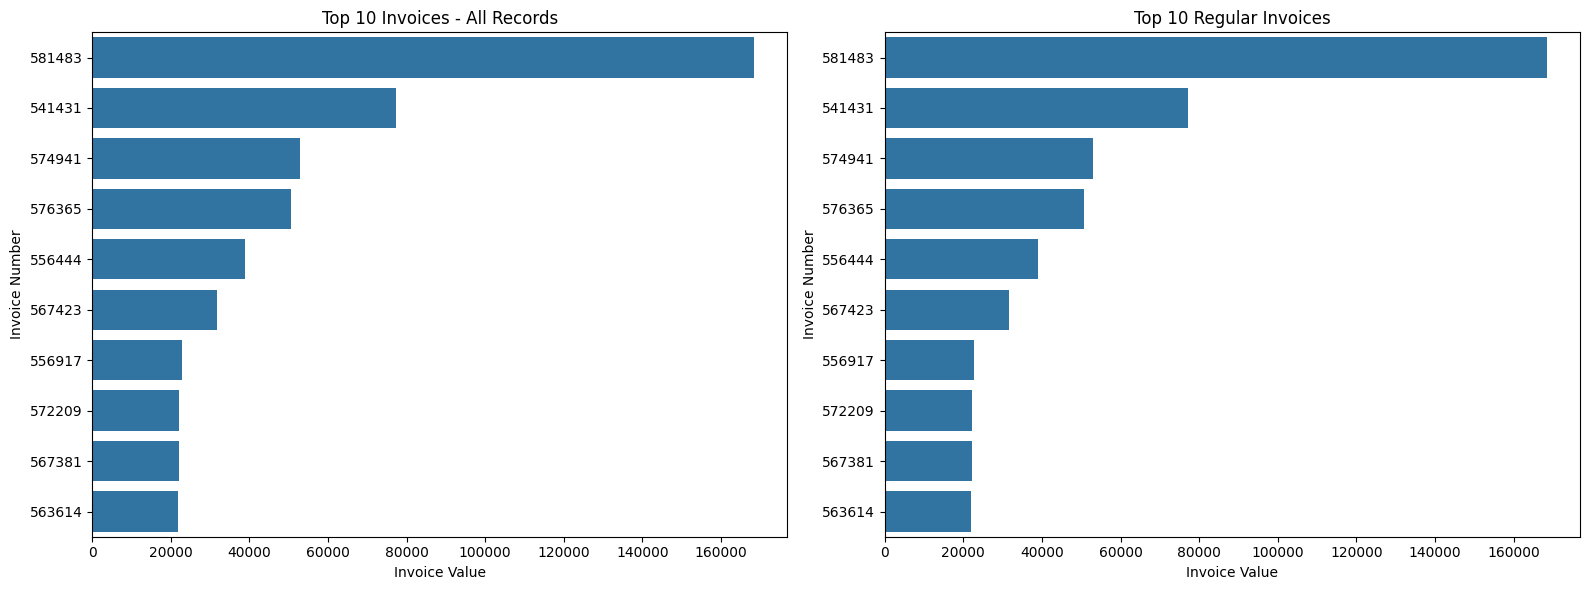

In [109]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(data=largest_invoices,x='Invoice_Value',y='InvoiceNo',ax=axes[0])
axes[0].set_title('Top 10 Invoices - All Records')
axes[0].set_xlabel('Invoice Value')
axes[0].set_ylabel('Invoice Number')

sns.barplot(data=largest_regular_invoices,x='Invoice_Value',y='InvoiceNo',ax=axes[1])
axes[1].set_title('Top 10 Regular Invoices')
axes[1].set_xlabel('Invoice Value')
axes[1].set_ylabel('Invoice Number')

plt.tight_layout()
plt.show()

Invoice-level analysis was performed by grouping transaction records by InvoiceNo. For each invoice, the total invoice value, number of distinct products, and total quantity were calculated.

The largest invoices were identified and compared with the ranking obtained after excluding cancelled invoices. This comparison helps evaluate whether cancellations affect the identification of the highest-value transactions.

##---

# Part 5 — Matplotlib Visualizations

### Q25. Product revenue comparison
Create a horizontal bar chart for the top 10 products by revenue. Include a clear title, axis labels, readable product labels, and an appropriate figure size.

### Q26. Monthly sales trend
Create a line chart of monthly revenue. Add markers, grid lines, axis labels, and a title. Ensure the months are sorted chronologically and explain the main trend.

In [110]:
# Q25
top_revenue = (sales.groupby('StockCode', as_index=False)['Revenue'].sum().sort_values('Revenue', ascending=False).head(10))
top_revenue['Description'] = top_revenue['StockCode'].map(product_names)
top_revenue

,StockCode,Revenue,Description
3930,DOT,206248.77,DOTCOM POSTAGE
1313,22423,174156.54,REGENCY CAKESTAND 3 TIER
2470,23843,168469.60,"PAPER CRAFT , LITTLE BIRDIE"
3424,85123A,104462.75,WHITE HANGING HEART T-LIGHT HOLDER
2678,47566,99445.23,PARTY BUNTING
3404,85099B,94159.81,JUMBO BAG RED RETROSPOT
2024,23166,81700.92,MEDIUM CERAMIC TOP STORAGE JAR
3933,POST,78101.88,POSTAGE
3931,M,77750.27,Manual
1946,23084,66870.03,RABBIT NIGHT LIGHT


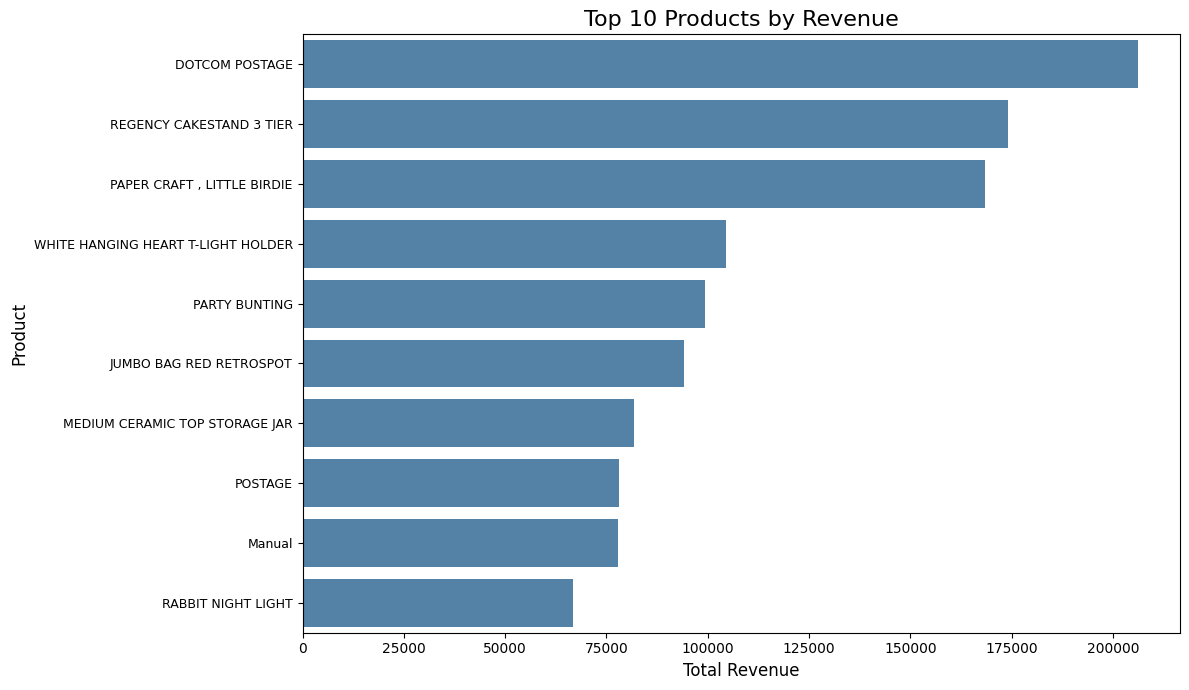

In [111]:
# Q25
plt.figure(figsize=(12, 7))
sns.barplot(data=top_revenue,x='Revenue',y='Description',color='steelblue')

plt.title('Top 10 Products by Revenue', fontsize=16)
plt.xlabel('Total Revenue', fontsize=12)
plt.ylabel('Product', fontsize=12)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

In [112]:
top_revenue_plot = top_revenue.sort_values('Revenue', ascending=True)

A horizontal bar chart was created to visualize the top 10 products by total revenue. Product descriptions were displayed on the vertical axis, while total revenue was displayed on the horizontal axis. The chart provides a clear comparison of revenue contribution across the highest-performing products.

In [113]:
# Q26
monthly_revenue = monthly_revenue.sort_values('Date')

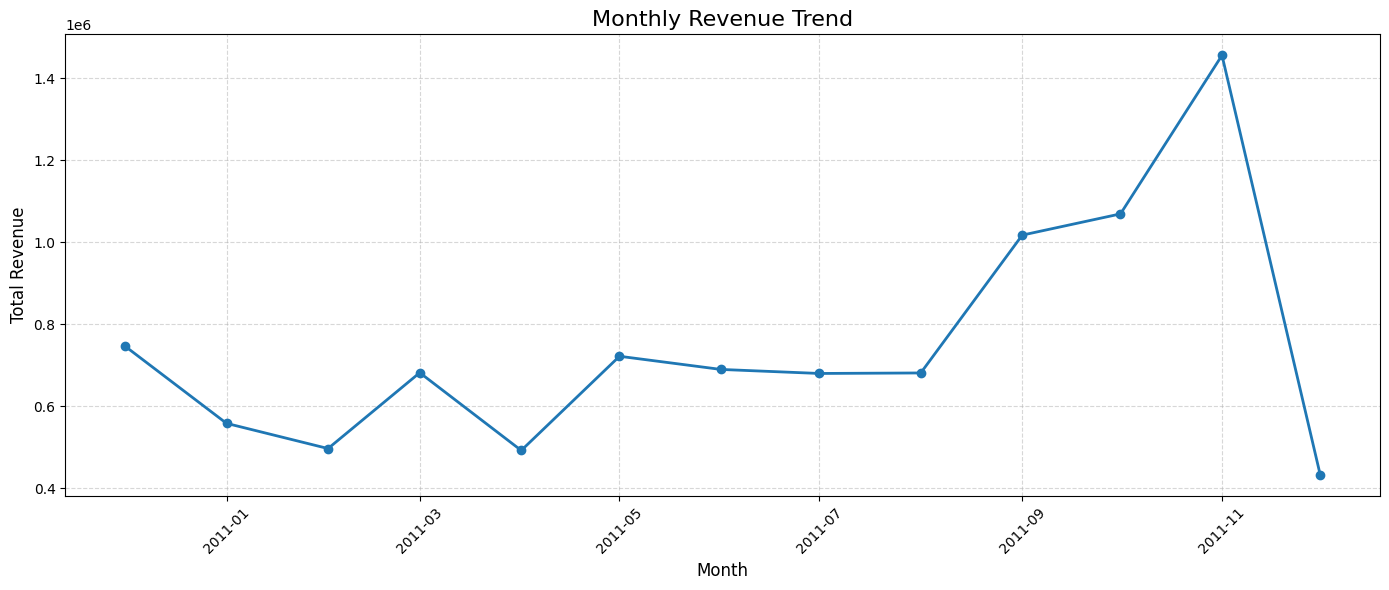

In [114]:
plt.figure(figsize=(14, 6))
plt.plot(monthly_revenue['Date'],monthly_revenue['Revenue'],marker='o',linewidth=2)

plt.title('Monthly Revenue Trend', fontsize=16)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Revenue', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

A line chart was created to visualize the monthly revenue trend over time. Circular markers were added to highlight individual monthly values, while grid lines improved readability.

The chronological ordering of months makes it easier to identify revenue growth, declines, and fluctuations over time.

---

# Part 6 — Seaborn Visualizations (Questions 27–28)

### Q27. Revenue distribution and outliers
Use a Seaborn boxplot to visualize the distribution of invoice values or transaction revenue. Handle extreme values thoughtfully: show the full distribution first, then optionally create a second view with a justified range. Explain what the outliers may represent.

### Q28. Correlation and final interactive dashboard chart
Choose suitable numeric features and create a Seaborn correlation heatmap with annotations. Then create at least one Plotly interactive chart (for example, monthly revenue by country or top products by revenue) with a meaningful hover tooltip. Write two insights from the visualizations.




In [115]:
# Plotly chart workspace

In [116]:
# Q27
invoice_values = invoice_analysis['Invoice_Value'].dropna()

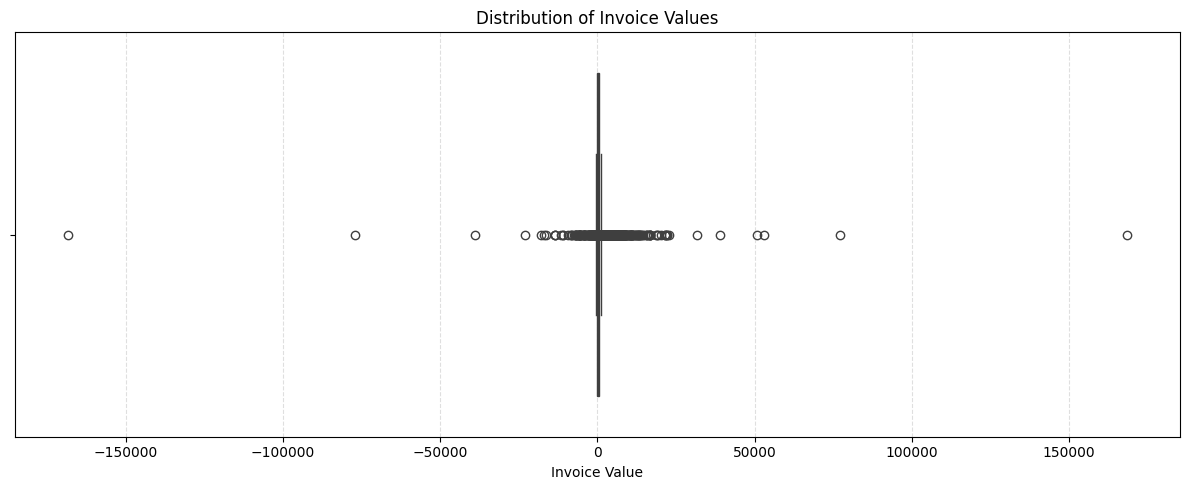

In [117]:
plt.figure(figsize=(12, 5))
sns.boxplot(x=invoice_values)

plt.title('Distribution of Invoice Values')
plt.xlabel('Invoice Value')
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

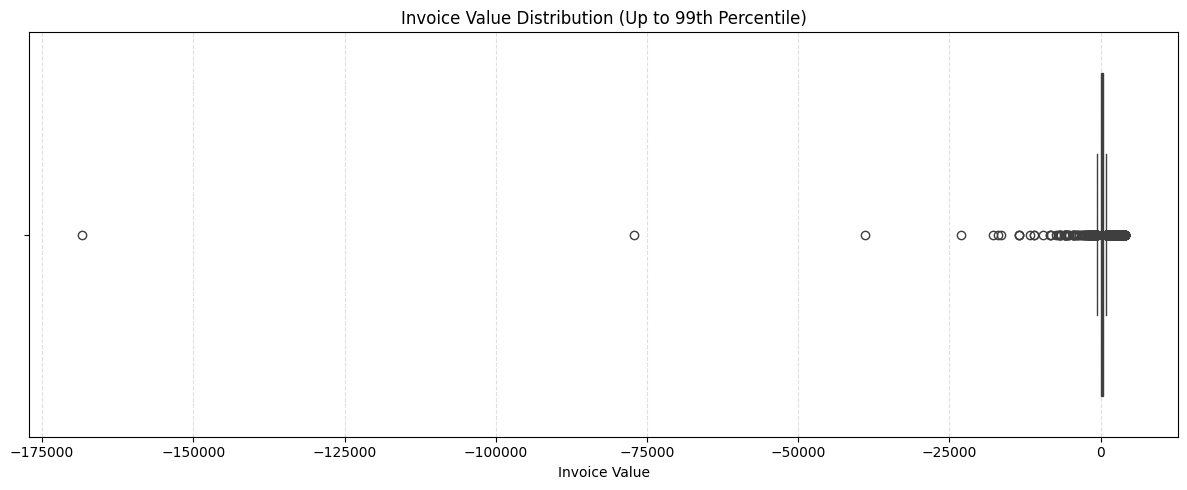

In [118]:
upper_limit = invoice_values.quantile(0.99)
filtered_invoice_values = invoice_values[invoice_values <= upper_limit]

plt.figure(figsize=(12, 5))
sns.boxplot(x=filtered_invoice_values)

plt.title('Invoice Value Distribution (Up to 99th Percentile)')
plt.xlabel('Invoice Value')
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [119]:
outliers = invoice_analysis[invoice_analysis['Invoice_Value'] > upper_limit].sort_values('Invoice_Value', ascending=False)
outliers.head(10)

,InvoiceNo,Invoice_Value,Distinct_Products,Total_Quantity,Is_Cancelled
22025,581483,168469.60,1,80995,False
2303,541431,77183.60,1,74215,False
18776,574941,52940.94,101,14149,False
19468,576365,50653.91,99,13956,False
9741,556444,38970.00,1,60,False
15046,567423,31698.16,12,12572,False
9951,556917,22775.93,138,15049,False
17393,572209,22206.00,7,1920,False
15038,567381,22104.80,12,6760,False
13240,563614,21880.44,97,12196,False


In [120]:
print(f"upper Limit: {upper_limit}")
print(f"number of High-Value Invoices: {len(outliers)}")
print(f"percentage: {round(len(outliers) / len(invoice_values) * 100, 2)} %")

upper Limit: 4106.868799999996
number of High-Value Invoices: 259
percentage: 1.0 %


A Seaborn boxplot was used to examine the distribution of invoice values and identify potential outliers. The full distribution was displayed first, followed by a second visualization limited to the 99th percentile to improve readability.

Extreme values may represent bulk purchases, high-value transactions, business customers, returns, cancellations, or potential data quality issues. Therefore, outliers should be investigated rather than automatically removed.

In [121]:
# Q28
correlation_data = clean_df[['Quantity', 'UnitPrice', 'Revenue']].copy()

In [122]:
correlation_matrix = correlation_data.corr()
correlation_matrix

,Quantity,UnitPrice,Revenue
Quantity,1.000000,-0.001241,0.886712
UnitPrice,-0.001241,1.000000,-0.162043
Revenue,0.886712,-0.162043,1.000000


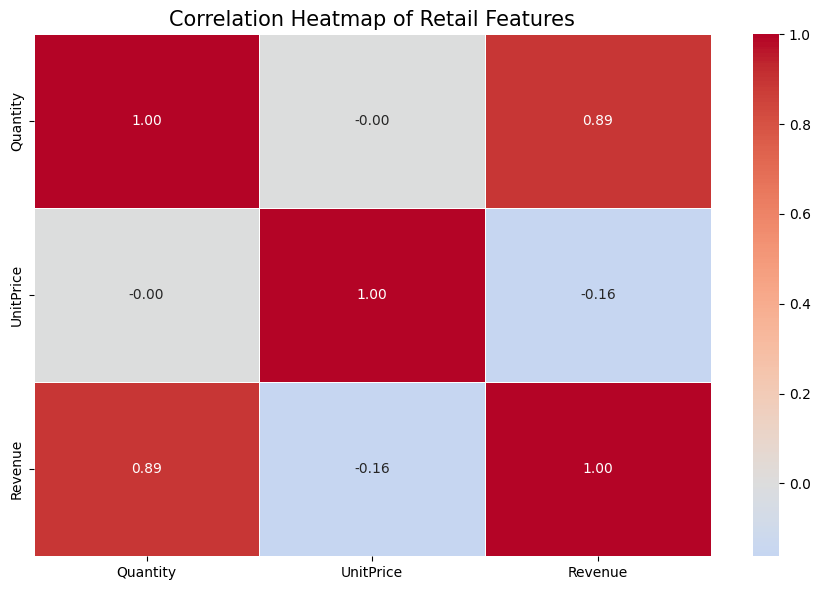

In [123]:
plt.figure(figsize=(9, 6))
sns.heatmap(correlation_matrix,annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.5,center=0)

plt.title('Correlation Heatmap of Retail Features', fontsize=15)
plt.tight_layout()
plt.show()

Revenue shows a relationship with both quantity and unit price, since it is calculated as the product of these two variables. This highlights how sales volume and product pricing contribute to revenue generation.

In [124]:
plotly_sales = clean_df[clean_df['Quantity'] > 0].copy()

plotly_top_products = (plotly_sales.groupby('StockCode', as_index=False).agg(Revenue=('Revenue', 'sum')).sort_values('Revenue', ascending=False).head(10))
plotly_top_products['Description'] = (plotly_top_products['StockCode'].map(product_names))

plotly_top_products

,StockCode,Revenue,Description
3930,DOT,206248.77,DOTCOM POSTAGE
1313,22423,174156.54,REGENCY CAKESTAND 3 TIER
2470,23843,168469.60,"PAPER CRAFT , LITTLE BIRDIE"
3424,85123A,104462.75,WHITE HANGING HEART T-LIGHT HOLDER
2678,47566,99445.23,PARTY BUNTING
3404,85099B,94159.81,JUMBO BAG RED RETROSPOT
2024,23166,81700.92,MEDIUM CERAMIC TOP STORAGE JAR
3933,POST,78101.88,POSTAGE
3931,M,77750.27,Manual
1946,23084,66870.03,RABBIT NIGHT LIGHT


In [125]:
fig = px.bar(
    plotly_top_products.sort_values('Revenue'),
    x='Revenue',
    y='Description',
    orientation='h',
    title='Top 10 Products by Revenue',
    labels={
        'Revenue': 'Total Revenue',
        'Description': 'Product'
    },
    hover_data={
        'StockCode': True,
        'Revenue': ':.2f'
    }
)

fig.update_layout(
    width=1100,
    height=650,
    template='plotly_white',
    yaxis_title='Product',
    xaxis_title='Total Revenue'
)

fig.show()

small number of products may generate a larger share of revenue, highlighting potentially important products for business performance.


## Final Project Conclusion

Write a concise conclusion containing:

1. The three most important data-quality issues you discovered.
2. The cleaning decisions you made and why.
3. The top product and top country by revenue.
4. One important trend in sales, customers, or returns.
5. Three actionable business recommendations.

## Publishing and Submission

- Restart the kernel and run all cells from top to bottom.
- Make sure your notebook contains no errors and all charts are visible.
- Publish the completed notebook publicly on Kaggle or GitHub.
- Publish a LinkedIn post describing your **3 most interesting findings** and include the notebook link.
- Submit both links: **Notebook URL** and **LinkedIn post URL**.


## Conclusion

The Online Retail dataset revealed three major data-quality issues: missing values in `CustomerID` (135,037 records) and `Description` (112 records), 10,587 rows with negative quantities indicating returns, and unusual pricing values, including 2,510 zero-price records and 2 negative-price records.

To improve data quality, exact duplicate rows were removed, missing product descriptions were filled using the most frequent description for each `StockCode` where possible, and appropriate data types were assigned. Missing `CustomerID` values were retained for general sales analysis but excluded from customer-level analysis. Returns and unusual prices were flagged rather than automatically deleted to preserve potentially valuable business information.

The highest-revenue product was **DOTCOM POSTAGE (DOT)**, generating **206,248.77**, while the **United Kingdom** was the top-performing country, generating **8,979,619.97** in revenue.

An important sales trend was that **November 2011 recorded the highest monthly revenue (1,456,145.80)**, while December 2011 recorded the lowest (432,701.06). The analysis also identified customer **14646** as the highest-spending customer, with total spending of **279,489.02**.

### Business Recommendations

1. **Optimize inventory:** Prioritize high-demand products and monitor stock levels to prevent shortages and missed sales.
2. **Improve customer retention:** Develop loyalty programs and personalized offers for high-value customers.
3. **Reduce returns and investigate pricing:** Analyze the reasons behind returned quantities and review zero or negative prices to identify operational or data-entry issues.

Overall, this analysis demonstrates how data cleaning and exploratory data analysis can transform raw retail transactions into actionable business insights.